# 33 | LB 22.2683156 · Public Packings + FQ Quench

Every packing published for this competition, plus one fq quench of each tilted one: 487 submission-shaped CSV files from 60 public notebooks and 13 datasets, 29,124 distinct packings, each judged by the hosts' own metric code, the best accepted one kept for every n.

| | |
|---|---|
| result | **LB 22.2683156169 (public leaderboard, submission 57715860, read 2026-10-27 23:52 UTC)** |
| beats | [ntumlnoob's First 22.268681355 Public Code](https://www.kaggle.com/code/ntumlnoob/first-22-268681355-public-code-with-explanation), the best public notebook Kaggle displays: 22.268681355 (Code tab, read 2026-10-27 22:40 UTC) |
| runtime | 36 min (2,130 s in the log of public V4) on Kaggle CPU, internet off |


**What V5 adds.** [ntumlnoob's First 22.268681355 Public Code](https://www.kaggle.com/code/ntumlnoob/first-22-268681355-public-code-with-explanation) (run 2026-10-27 20:33 UTC from a private portfolio)
holds the shortest public packing on every one of the 1000 puzzles, so a merge of all public files only ties it:
22.268681355090 with this metric. We then ran Evan Daniel's `fq quench` once on each of the
547 puzzles that are not at the grid, starting from that best public packing. It shortened
28 of them; a contact LP polish adds 6 and the width-1 border rule on
the new sides 12. The hosts' metric accepts all 46, and they are the whole difference
to the best public notebook: 3.7e-4 (section 6). Those packings, and the scripts that made them, are in the attached dataset
[busyaprime/squares-in-squares-fq-quenched-packings](https://www.kaggle.com/datasets/busyaprime/squares-in-squares-fq-quenched-packings); the cells below certify them exactly like every public input.

The merged side lengths obey the two closure rules a merge can apply for free: deleting squares from a larger
packing finds 0 improvements, and adding a width-1 border to a smaller packing finds
7 worth 1.5e-12 in total. The leaderboard's first place is at
22.0904187465 (Cats and boxes, board downloaded 2026-10-27 23:52 UTC), 0.178
below this file. That gap is new packings, not a better merge.

So this is the one file to start from, with every packing proven by the code that scores it. Fork it, add packings
of your own to the inputs, and the cells below keep whichever is shorter.

157 of the 28,894 packings certified so far (shortest first per n, out of 29,124) fail that code (157 overlap). In submission files they occur only in 2 notebooks far from the frontier (avikdas567/optimal-packing-of-n-unit-squares-sat-dynamics at 25.869, zkskhurram/kaggle-squares-in-squares at 28.938). The others sit in non-submission files: 143 in `motif_coordinates.csv` of lucifer19/think-pack-ship-transparent-inputs. None of the top public files carries one: the public merges validate well.

In [1]:
import csv, hashlib, json, math, multiprocessing as mp, os, sys, time
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from IPython.display import Markdown, display

# House style, spliced from engine/33_style.py (repo commit 76f5d9b5+local).
INK = "#1f2328"
MUTED = "#8b949e"
GRID = "#e6e8eb"
ACCENT = "#d9480f"
SECOND = "#1c7ed6"
PALETTE = [ACCENT, SECOND, "#495057", "#adb5bd", "#2b8a3e", "#862e9c"]
def apply() -> None:
    """Set matplotlib defaults. Safe to call more than once."""
    import matplotlib as mpl
    mpl.rcParams.update({
        "figure.figsize": (9, 4.6), "figure.dpi": 110, "savefig.dpi": 160,
        "figure.facecolor": "white", "axes.facecolor": "white",
        "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.labelsize": 11, "axes.labelcolor": INK, "text.color": INK,
        "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 2.0, "legend.frameon": False, "legend.fontsize": 10,
    })
def label_point(ax, x, y, text: str, color: str = ACCENT) -> None:
    """Print the number that matters on the chart, next to the point it describes."""
    ax.annotate(text, (x, y), xytext=(6, 6), textcoords="offset points", color=color,
                fontsize=11, fontweight="semibold")
apply()
T0 = time.time()
INPUT = Path("/kaggle/input")
COLS = ("n", "square_id", "x", "y", "angle")
csv.field_size_limit(10**9)
# os.cpu_count() can report the host's cores inside a container; the affinity mask is what this session may use.
NPROC = min(4, len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count())
print(f"python {sys.version.split()[0]}, os.cpu_count() {os.cpu_count()}, using {NPROC} processes")

python 3.13.15, os.cpu_count() 4, using 4 processes


## 1. The metric, verbatim

The hosts' metric notebook ([metric/squares-in-squares](https://www.kaggle.com/code/metric/squares-in-squares)) is
written to `sis_metric.py` unchanged. A float SAT test sorts pairs into separated, overlapping and undecided; the
undecided ones (within 1e-8) go to mpmath interval arithmetic at 50, 100, 200 and 500 digits. A pair still undecided
at 500 digits fails the puzzle. Nothing below re-implements any of it.

In [2]:
%%writefile sis_metric.py
# Verbatim copy of the competition metric, Kaggle notebook metric/squares-in-squares
# (https://www.kaggle.com/code/metric/squares-in-squares), pulled 2026-10-27 with `kaggle kernels pull -m`.
# Do not edit: 33_merge.py and the public notebook accept a packing only if this code accepts it.
"""Metric for the "Packing N Unit Squares into the Smallest Square" competition.

Participants submit packings of n unit squares (n=1..1000) inside a bounding
square.  Each square is specified by its center (x, y) and rotation angle.
Coordinates must be plain decimal literals, optionally in scientific notation
(e.g. ``2.70710678118654752440`` or ``1.5e-3``).  Symbolic / closed-form
expressions are not accepted -- submit their decimal expansion instead, at as
many digits as you like.

Scoring
-------
For each puzzle n the bounding side length L is measured
translation-invariantly as ``max(max_x - min_x, max_y - min_y)`` over all
corners.  The per-puzzle score is the excess over the area lower bound

    score(n) = L / sqrt(n) - 1

which is 0.0 exactly when the packing achieves the area lower bound (only
possible for perfect squares packed on the grid) and grows above 0 as the
bounding square wastes area.  **Lower is better**; total score is the sum
across n=1..N.

+-------------------+---------------------------------------------------------+
| Condition         | Score                                                   |
+===================+=========================================================+
| feasible packing  | L / sqrt(n) - 1     (>= 0 always)                       |
+-------------------+---------------------------------------------------------+
| infeasible/invalid| L_0 / sqrt(n) - 1   (grid ceiling — no worse than       |
|                   |                      submitting the trivial grid)       |
+-------------------+---------------------------------------------------------+

For reference: ``L_B = sqrt(n)`` is the area lower bound and
``L_0 = ceil(sqrt(n))`` is the trivial grid packing.  The best-known side
length plays no part -- beating a record just yields a smaller excess -- so
this metric reads no baseline values at all.

Feasibility is checked with interval arithmetic (mpmath) at escalating
precision to certify that no two squares overlap.

Kaggle entry point
------------------
``score(solution, submission, row_id_column_name)`` — called by the Kaggle
backend.  ``solution`` is a DataFrame loaded from ``solution.csv``; only its
``n`` column is read, to fix which puzzles are scored (and which absent ones
are charged the grid ceiling).  ``submission`` is the participant CSV with
columns ``n, square_id, x, y, angle``.

As a side effect it writes ``submission_details.csv``, one row per puzzle with
columns ``n`` and ``L``::

    n,L
    1,1.00000000000000000000000000000000000000000000000000
    2,2.00000000000000000000000000000000000000000000000000
    ...

``L`` is the measured bounding side for puzzle n -- not the per-puzzle score --
written with exactly 50 digits after the decimal point.  Those digits are
significant: L is measured in ``L_DPS``-digit mpmath arithmetic straight from
the submitted decimal strings, not from a double.  Puzzles with no accepted L
(absent from the submission, unparseable, failing column validation, or
rejected as infeasible) are written as zero.
"""

import contextlib
import csv
import io
import math
import multiprocessing
import re
from collections import defaultdict
from collections.abc import Callable, Sequence
from dataclasses import dataclass, field
from fractions import Fraction
from pathlib import Path

import mpmath
import pandas as pd

# ---------------------------------------------------------------------------
# interval
# ---------------------------------------------------------------------------

IVal = mpmath.ctx_iv.ivmpf

# Working precision for the (non-interval) measurement of the bounding side L,
# and the number of digits after the decimal point written for it in
# submission_details.csv.  The margin between the two keeps every written digit
# correct: the only rounding is in the trig of the corner computation, tens of
# digits below the last digit reported.
L_DPS = 60
L_DECIMALS = 50


@contextlib.contextmanager
def working_dps(dps: int):
    """Run a block with both mpmath contexts at ``dps`` digits, then restore them.

    ``mpmath.iv`` carries its own precision, independent of ``mpmath.mp``:
    setting only ``mpmath.mp.dps`` leaves every interval operation at the
    default 53 bits, which caps what a contact can be certified to at ~1e-13 no
    matter how far the escalation sequence climbs.  Both contexts are set here
    because the interval work is interleaved with plain ``mp`` arithmetic.

    >>> with working_dps(500):
    ...     width = mpmath.mpf(mpmath.iv.mpf('0.1').delta)
    >>> width < mpmath.mpf(10) ** -500
    True
    """
    old_iv_dps = mpmath.iv.dps
    old_mp_dps = mpmath.mp.dps
    try:
        mpmath.iv.dps = dps
        mpmath.mp.dps = dps
        yield
    finally:
        mpmath.iv.dps = old_iv_dps
        mpmath.mp.dps = old_mp_dps


def make_interval(value: str, dps: int = 50) -> IVal:
    with working_dps(dps):
        return mpmath.iv.mpf(value)


def iv_cos(x: IVal) -> IVal:
    return mpmath.iv.cos(x)


def iv_sin(x: IVal) -> IVal:
    return mpmath.iv.sin(x)


_ESCALATION_SEQUENCE = [50, 100, 200, 500]


def escalate(
    fn: Callable[[int], bool | None],
    max_dps: int = 500,
    start_dps: int = 50,
) -> bool | None:
    for dps in _ESCALATION_SEQUENCE:
        if dps < start_dps:
            continue
        if dps > max_dps:
            break
        result = fn(dps)
        if result is not None:
            return result
    return None


def iv_le(a: IVal, b: IVal) -> bool | None:
    """Certified less-or-equal: True if a <= b, False if a > b, None if undecided.

    Comparing two overlapping intervals is indeterminate.  mpmath 1.3 reports
    that as None, 1.4 raises ValueError; both mean "undecided" here.
    """
    try:
        return a <= b
    except ValueError:
        return None


def iv_min(values: Sequence[IVal]) -> IVal:
    """Interval extension of ``min``: the tightest interval containing the true minimum.

    Comparison operators are useless for this -- two overlapping intervals have
    no determinate order -- so take it endpoint-wise instead.  min of the lower
    bounds is a lower bound on the true min, and min of the upper bounds is an
    upper bound on it, whichever element turns out to be smallest.
    """
    return mpmath.iv.mpf([min(v.a for v in values), min(v.b for v in values)])


def iv_max(values: Sequence[IVal]) -> IVal:
    """Interval extension of ``max``. See :func:`iv_min`."""
    return mpmath.iv.mpf([max(v.a for v in values), max(v.b for v in values)])


# ---------------------------------------------------------------------------
# parser
# ---------------------------------------------------------------------------

# Bounds the cost of parsing one coordinate.  Far above any useful precision
# (L is reported to 50 decimals), so no honest submission comes near it.
_MAX_LITERAL_CHARS = 100

# Coordinate, angle, and sweep bounds.  For n <= 1000 unit squares, valid
# packings have side L <= 32.  Bounding magnitudes prevents float64/mpmath
# discrepancies and precision loss under extreme translation or rotation.
_MAX_COORD = 1e4
_MAX_ANGLE = 100.0
_AABB_PAD = 1e-7

_DECIMAL_RE = re.compile(r'^[+-]?(\d+\.?\d*|\.\d+)([eE][+-]?\d+)?$')


def _is_decimal(s: str) -> bool:
    return len(s) <= _MAX_LITERAL_CHARS and bool(_DECIMAL_RE.match(s.strip()))


def _check_decimal(s: str) -> str:
    """Return the stripped literal, or raise if it is not a plain decimal.

    >>> _check_decimal(" 2.70710678118654752440 ")
    '2.70710678118654752440'
    >>> _check_decimal("1.5e-3")
    '1.5e-3'
    >>> _check_decimal("1 + sqrt(2)")
    Traceback (most recent call last):
        ...
    ValueError: not a decimal number: '1 + sqrt(2)'
    """
    s = s.strip()
    if not _is_decimal(s):
        shown = s if len(s) <= 40 else s[:40] + '...'
        raise ValueError(f'not a decimal number: {shown!r}')
    return s


def parse_value(s: str, dps: int = 50) -> IVal:
    """Parse a decimal literal into an enclosing interval at ``dps`` digits."""
    return make_interval(_check_decimal(s), dps)


def parse_value_mp(s: str, dps: int = L_DPS) -> mpmath.mpf:
    """Parse a decimal literal into an ``mpf`` at ``dps`` digits.

    >>> mpmath.nstr(parse_value_mp("2.70710678118654752440"), 21, strip_zeros=False)
    '2.70710678118654752440'
    """
    s = _check_decimal(s)
    old_dps = mpmath.mp.dps
    try:
        mpmath.mp.dps = dps
        return mpmath.mpf(s)
    finally:
        mpmath.mp.dps = old_dps


def parse_value_float(s: str) -> float:
    """Parse a decimal literal to float.

    Values too large for a double are rejected rather than becoming ``inf``,
    which would poison every downstream geometry check:

    >>> parse_value_float("3.5")
    3.5
    >>> parse_value_float("-2.5")
    -2.5
    >>> parse_value_float("1.5e-3")
    0.0015
    >>> parse_value_float("1e400")
    Traceback (most recent call last):
        ...
    ValueError: value out of range for a double: '1e400'
    """
    s = _check_decimal(s)
    value = float(s)
    if not math.isfinite(value):
        raise ValueError(f'value out of range for a double: {s!r}')
    return value


# ---------------------------------------------------------------------------
# scoring
# ---------------------------------------------------------------------------


def score_puzzle(n: int, s_certified: float) -> float:
    """Score a single puzzle: L / sqrt(n) - 1 (lower is better).

    Result is >= 0 for any feasible packing (equality only for perfect-square
    grid packings).  The best-known side length s* plays no part: beating a
    record simply yields a smaller excess.

    >>> score_puzzle(4, 2.0)
    0.0
    >>> round(score_puzzle(5, 2.707), 6)
    0.210607
    >>> score_puzzle(4, 4.0)
    1.0
    """
    L_B = math.sqrt(n)
    return s_certified / L_B - 1.0


def infeasible_score(n: int) -> float:
    """Penalty score for an infeasible / invalid submission for puzzle n.

    Equal to submitting the trivial grid packing: L_0 / sqrt(n) - 1.
    """
    return math.ceil(math.sqrt(n)) / math.sqrt(n) - 1.0


# ---------------------------------------------------------------------------
# geometry
# ---------------------------------------------------------------------------


@dataclass
class Square:
    x: float
    y: float
    angle: float
    x_str: str = ''
    y_str: str = ''
    angle_str: str = ''
    _corners_float: list[tuple[float, float]] = field(default_factory=list, repr=False)

    def corners_float(self) -> list[tuple[float, float]]:
        if not self._corners_float:
            self._corners_float = compute_corners_float(self.x, self.y, self.angle)
        return self._corners_float


def compute_corners_float(cx: float, cy: float, angle: float) -> list[tuple[float, float]]:
    """Return the four corners of a unit square centered at (cx, cy) rotated by angle.

    >>> corners = compute_corners_float(0.5, 0.5, 0.0)
    >>> [(round(x, 1), round(y, 1)) for x, y in corners]
    [(1.0, 1.0), (0.0, 1.0), (0.0, 0.0), (1.0, 0.0)]
    """
    c = math.cos(angle)
    s = math.sin(angle)
    h = 0.5
    dx1, dy1 = h * c - h * s, h * s + h * c
    dx2, dy2 = -h * c - h * s, -h * s + h * c
    return [
        (cx + dx1, cy + dy1),
        (cx + dx2, cy + dy2),
        (cx - dx1, cy - dy1),
        (cx - dx2, cy - dy2),
    ]


def compute_corners_mp(cx: mpmath.mpf, cy: mpmath.mpf, angle: mpmath.mpf) -> list[tuple[mpmath.mpf, mpmath.mpf]]:
    """``compute_corners_float`` at the ambient ``mpmath.mp`` precision."""
    c = mpmath.cos(angle)
    s = mpmath.sin(angle)
    h = mpmath.mpf(1) / 2
    dx1, dy1 = h * c - h * s, h * s + h * c
    dx2, dy2 = -h * c - h * s, -h * s + h * c
    return [
        (cx + dx1, cy + dy1),
        (cx + dx2, cy + dy2),
        (cx - dx1, cy - dy1),
        (cx - dx2, cy - dy2),
    ]


def measure_side_mp(squares: list['Square'], dps: int = L_DPS) -> mpmath.mpf:
    """Bounding side ``max(max_x - min_x, max_y - min_y)`` at ``dps`` digits.

    Measured from the submitted decimal strings translated relative to Square 0,
    so coordinates carry high precision without loss due to global translation.

    >>> unit = Square(0.5, 0.5, 0.0, x_str="0.5", y_str="0.5", angle_str="0")
    >>> measure_side_mp([unit])
    mpf('1.0')
    """
    old_dps = mpmath.mp.dps
    try:
        mpmath.mp.dps = dps
        xs: list[mpmath.mpf] = []
        ys: list[mpmath.mpf] = []
        x0 = parse_value_mp(squares[0].x_str, dps) if squares else mpmath.mpf(0)
        y0 = parse_value_mp(squares[0].y_str, dps) if squares else mpmath.mpf(0)
        for sq in squares:
            corners = compute_corners_mp(
                parse_value_mp(sq.x_str, dps) - x0,
                parse_value_mp(sq.y_str, dps) - y0,
                parse_value_mp(sq.angle_str, dps),
            )
            for x, y in corners:
                xs.append(x)
                ys.append(y)
        return max(max(xs) - min(xs), max(ys) - min(ys))
    finally:
        mpmath.mp.dps = old_dps


def compute_corners_interval(cx_iv: IVal, cy_iv: IVal, angle_iv: IVal) -> list[tuple[IVal, IVal]]:
    c = iv_cos(angle_iv)
    s = iv_sin(angle_iv)
    h = mpmath.iv.mpf('0.5')
    dx1, dy1 = h * c - h * s, h * s + h * c
    dx2, dy2 = -h * c - h * s, -h * s + h * c
    return [
        (cx_iv + dx1, cy_iv + dy1),
        (cx_iv + dx2, cy_iv + dy2),
        (cx_iv - dx1, cy_iv - dy1),
        (cx_iv - dx2, cy_iv - dy2),
    ]


def compute_aabb(
    corners: list[tuple[float, float]],
    pad: float = _AABB_PAD,
) -> tuple[float, float, float, float]:
    xs = [c[0] for c in corners]
    ys = [c[1] for c in corners]
    return (min(xs) - pad, min(ys) - pad, max(xs) + pad, max(ys) + pad)


def aabb_overlap(
    a: tuple[float, float, float, float],
    b: tuple[float, float, float, float],
) -> bool:
    return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])


def _project_corners_float(corners: list[tuple[float, float]], ax: float, ay: float) -> tuple[float, float]:
    projs = [ax * cx + ay * cy for cx, cy in corners]
    return (min(projs), max(projs))


def sat_check_float(sq1: Square, sq2: Square, undecided_tol: float = 1e-8) -> str:
    """Check overlap between two unit squares using the Separating Axis Theorem.

    Returns ``"separated"``, ``"overlapping"``, or ``"undecided"``.

    >>> sat_check_float(Square(0.5, 0.5, 0.0), Square(5.0, 5.0, 0.0))
    'separated'
    >>> sat_check_float(Square(0.5, 0.5, 0.0), Square(0.6, 0.6, 0.0))
    'overlapping'
    """
    c1 = sq1.corners_float()
    c2 = sq2.corners_float()

    axes = _get_axes_float(sq1.angle, sq2.angle)

    min_overlap = float('inf')
    for ax, ay in axes:
        min1, max1 = _project_corners_float(c1, ax, ay)
        min2, max2 = _project_corners_float(c2, ax, ay)
        overlap = min(max1, max2) - max(min1, min2)
        if overlap < -undecided_tol:
            return 'separated'
        min_overlap = min(min_overlap, overlap)

    if min_overlap > undecided_tol:
        return 'overlapping'
    return 'undecided'


def _get_axes_float(angle1: float, angle2: float) -> list[tuple[float, float]]:
    c1, s1 = math.cos(angle1), math.sin(angle1)
    c2, s2 = math.cos(angle2), math.sin(angle2)
    return [(c1, s1), (-s1, c1), (c2, s2), (-s2, c2)]


def sat_check_interval(
    sq1_corners: list[tuple[IVal, IVal]],
    sq2_corners: list[tuple[IVal, IVal]],
    angle1_iv: IVal,
    angle2_iv: IVal,
) -> bool | None:
    c1_iv, s1_iv = iv_cos(angle1_iv), iv_sin(angle1_iv)
    c2_iv, s2_iv = iv_cos(angle2_iv), iv_sin(angle2_iv)
    axes = [(c1_iv, s1_iv), (-s1_iv, c1_iv), (c2_iv, s2_iv), (-s2_iv, c2_iv)]

    has_undecided = False
    for ax, ay in axes:
        projs1 = [ax * cx + ay * cy for cx, cy in sq1_corners]
        projs2 = [ax * cx + ay * cy for cx, cy in sq2_corners]

        # Endpoint-wise, via iv_min/iv_max: ordering two overlapping intervals
        # with < is indeterminate, and skipping the projections that compare
        # indeterminately would narrow the span -- which shrinks the overlap and
        # biases the test towards wrongly certifying a pair as separated.
        min1, max1 = iv_min(projs1), iv_max(projs1)
        min2, max2 = iv_min(projs2), iv_max(projs2)

        overlap = iv_min([max1, max2]) - iv_max([min1, min2])
        le_result = iv_le(overlap, mpmath.iv.mpf('0'))
        if le_result is True:
            return True
        if le_result is None:
            has_undecided = True

    if has_undecided:
        return None
    return False


def sort_and_sweep(squares: list[Square]) -> list[tuple[int, int]]:
    n = len(squares)
    if n <= 1:
        return []

    aabbs = []
    for i, sq in enumerate(squares):
        corners = sq.corners_float()
        aabb = compute_aabb(corners)
        aabbs.append((i, aabb))

    aabbs.sort(key=lambda x: x[1][0])

    pairs = []
    for i_idx in range(n):
        i, aabb_i = aabbs[i_idx]
        for j_idx in range(i_idx + 1, n):
            j, aabb_j = aabbs[j_idx]
            if aabb_j[0] > aabb_i[2]:
                break
            if aabb_overlap(aabb_i, aabb_j):
                pairs.append((i, j) if i < j else (j, i))

    return pairs


def verify_puzzle(
    squares: list[Square],
) -> tuple[bool, str]:
    """Check that no two squares overlap, using float SAT then interval arithmetic.

    >>> s1 = Square(0.5, 0.5, 0.0, x_str="0.5", y_str="0.5", angle_str="0")
    >>> s2 = Square(1.5, 0.5, 0.0, x_str="1.5", y_str="0.5", angle_str="0")
    >>> verify_puzzle([s1, s2])
    (True, 'feasible')
    >>> verify_puzzle([Square(0.5, 0.5, 0.0), Square(0.6, 0.6, 0.0)])
    (False, 'Squares 0 and 1 overlap (float check)')
    """
    pairs = sort_and_sweep(squares)
    undecided_pairs = []
    for i, j in pairs:
        result = sat_check_float(squares[i], squares[j])
        if result == 'overlapping':
            return (False, f'Squares {i} and {j} overlap (float check)')
        if result == 'undecided':
            undecided_pairs.append((i, j))

    if undecided_pairs:

        def check_overlap_certified(dps: int) -> bool | None:
            # The whole pair loop runs inside the precision context: parsing at dps
            # digits is not enough, since every later interval operation widens its
            # result to whatever precision mpmath.iv is set to at the time.
            with working_dps(dps):
                still_undecided = []
                for i, j in undecided_pairs:
                    sq_i, sq_j = squares[i], squares[j]
                    cx_i = parse_value(sq_i.x_str, dps)
                    cy_i = parse_value(sq_i.y_str, dps)
                    ai = parse_value(sq_i.angle_str, dps)
                    cx_j = parse_value(sq_j.x_str, dps)
                    cy_j = parse_value(sq_j.y_str, dps)
                    aj = parse_value(sq_j.angle_str, dps)
                    corners_i = compute_corners_interval(cx_i, cy_i, ai)
                    corners_j = compute_corners_interval(cx_j, cy_j, aj)
                    result = sat_check_interval(corners_i, corners_j, ai, aj)
                    if result is False:
                        return False
                    if result is None:
                        still_undecided.append((i, j))
                if still_undecided:
                    return None
                return True

        result = escalate(check_overlap_certified)
        if result is False:
            return (False, 'Squares overlap (certified)')
        if result is None:
            return (False, 'Overlap undecidable at max precision')

    return (True, 'feasible')


# ---------------------------------------------------------------------------
# main / Kaggle entry point
# ---------------------------------------------------------------------------


class ParticipantVisibleError(Exception):
    pass


MAX_N = 1000
KAGGLE_CORES = 4
MIN_PUZZLES_FOR_MP = 4


def _parse_submission_csv(text: str) -> dict[int, list[dict]]:
    reader = csv.DictReader(io.StringIO(text))
    required_cols = {'n', 'square_id', 'x', 'y', 'angle'}
    if not required_cols.issubset(set(reader.fieldnames or [])):
        missing = required_cols - set(reader.fieldnames or [])
        raise ParticipantVisibleError(f'Missing columns: {missing}')

    puzzles: dict[int, list[dict]] = defaultdict(list)
    for row_num, row in enumerate(reader, start=2):
        try:
            n = int(row['n'])
        except (ValueError, TypeError):
            raise ParticipantVisibleError(f'Row {row_num}: invalid n value: {row["n"]!r}')
        if n < 1 or n > MAX_N:
            raise ParticipantVisibleError(f'Row {row_num}: n={n} out of range [1, {MAX_N}]')
        puzzles[n].append(row)

    return dict(puzzles)


def _validate_puzzle(n: int, rows: list[dict]) -> str | None:
    if len(rows) != n:
        return f'n={n}: expected {n} rows, got {len(rows)}'

    square_ids = set()
    for row in rows:
        try:
            sid = int(row['square_id'])
        except (ValueError, TypeError):
            return f'n={n}: invalid square_id: {row["square_id"]!r}'
        square_ids.add(sid)

    expected_ids = set(range(n))
    if square_ids != expected_ids:
        return f'n={n}: square_ids should be 0..{n - 1}, got {sorted(square_ids)}'

    return None


def _build_squares(n: int, rows: list[dict]) -> tuple[list[Square], mpmath.mpf]:
    rows_by_id = {int(r['square_id']): r for r in rows}

    raw_coords = []
    for sid in range(n):
        row = rows_by_id[sid]
        x_str = row['x'].strip()
        y_str = row['y'].strip()
        angle_str = row['angle'].strip()

        try:
            x_f = parse_value_float(x_str)
            y_f = parse_value_float(y_str)
            angle_f = parse_value_float(angle_str)
        except ValueError as e:
            raise ParticipantVisibleError(f'n={n}, square {sid}: cannot parse coordinates: {e}')

        if abs(x_f) > _MAX_COORD or abs(y_f) > _MAX_COORD:
            raise ParticipantVisibleError(f'n={n}, square {sid}: coordinate out of bounds (|x|, |y| must be <= {_MAX_COORD:g})')
        if abs(angle_f) > _MAX_ANGLE:
            raise ParticipantVisibleError(f'n={n}, square {sid}: angle out of bounds (|angle| must be <= {_MAX_ANGLE:g} radians)')

        raw_coords.append((sid, x_str, y_str, angle_str))

    x0_mp = parse_value_mp(raw_coords[0][1], L_DPS)
    y0_mp = parse_value_mp(raw_coords[0][2], L_DPS)
    two_pi = 2 * mpmath.pi

    squares = []
    for sid, x_str, y_str, angle_str in raw_coords:
        x_mp = parse_value_mp(x_str, L_DPS)
        y_mp = parse_value_mp(y_str, L_DPS)
        angle_mp = parse_value_mp(angle_str, L_DPS)

        dx_f = float(x_mp - x0_mp)
        dy_f = float(y_mp - y0_mp)
        angle_reduced_f = float(angle_mp % two_pi)

        squares.append(
            Square(
                x=dx_f,
                y=dy_f,
                angle=angle_reduced_f,
                x_str=x_str,
                y_str=y_str,
                angle_str=angle_str,
            )
        )

    return squares, measure_side_mp(squares)


def evaluate_single_puzzle(n: int, rows: list[dict]) -> tuple[int, float, str | None, str]:
    """Evaluate one puzzle, returning ``(n, score, L, reason)``.

    ``L`` is decimal text with ``L_DECIMALS`` digits after the point, and is
    reported only for a packing that passed the feasibility check: an
    unparseable, malformed, or overlapping puzzle gets None, so no L is
    published for a packing the metric rejected.  Text rather than a float
    because a double cannot hold those digits; the score itself is a double,
    taken from the same high-precision measurement.
    """
    error = _validate_puzzle(n, rows)
    if error:
        return (n, infeasible_score(n), None, error)

    try:
        squares, s_mp = _build_squares(n, rows)
    except ParticipantVisibleError as e:
        return (n, infeasible_score(n), None, str(e))

    feasible, reason = verify_puzzle(squares)
    if not feasible:
        return (n, infeasible_score(n), None, f'infeasible: {reason}')

    L_B = math.sqrt(n)
    if float(s_mp) < L_B - 1e-7:
        return (
            n,
            infeasible_score(n),
            None,
            f'infeasible: L={float(s_mp):.6f} is below area lower bound sqrt({n})={L_B:.6f}',
        )

    puzzle_score = max(0.0, score_puzzle(n, float(s_mp)))
    return (n, puzzle_score, _format_detail(s_mp), 'ok')


def _evaluate_puzzle_worker(args: tuple) -> tuple[int, float, str | None, str]:
    n, rows = args
    try:
        return evaluate_single_puzzle(n, rows)
    except Exception as e:  # noqa: BLE001 - one bad puzzle must not kill the pool
        return (n, infeasible_score(n), None, f'worker error: {e}')


def _evaluate_puzzles_parallel(
    puzzles: dict[int, list[dict]],
    puzzle_ns: set[int],
) -> tuple[float, list[tuple[int, float, str | None, str]]]:
    """Score every n in ``puzzle_ns``; rows for any other n are ignored."""
    work = [(n, rows) for n, rows in sorted(puzzles.items()) if n in puzzle_ns]

    if not work:
        results: list[tuple[int, float, str | None, str]] = []
    elif len(work) < MIN_PUZZLES_FOR_MP:
        results = [evaluate_single_puzzle(n, rows) for n, rows in work]
    else:
        with multiprocessing.Pool(processes=KAGGLE_CORES) as pool:
            results = pool.map(_evaluate_puzzle_worker, work)

    # Any scored n missing from the submission gets the grid-ceiling penalty
    # (lower-is-better metric — otherwise omitting a puzzle would improve the
    # total).
    seen = {n for n, _, _, _ in results}
    for n in puzzle_ns:
        if n not in seen:
            results.append((n, infeasible_score(n), None, 'missing from submission'))
    results.sort(key=lambda r: r[0])

    total = sum(puzzle_score for _, puzzle_score, _, _ in results)
    return total, results


def _format_detail(value: mpmath.mpf) -> str:
    """Decimal text for one per-puzzle L: exactly ``L_DECIMALS`` digits after the point.

    An ``mpf`` is a binary fraction (``man * 2**exp``), so it is converted
    exactly to a ``Fraction`` and rounded once, half-to-even, at the last
    written digit.  ``mpmath.nstr`` counts significant digits rather than
    decimal places, and ``format(mpf, '.50f')`` needs mpmath >= 1.4, so neither
    is usable here.

    >>> _format_detail(mpmath.mpf(2))[:12]
    '2.0000000000'
    >>> len(_format_detail(mpmath.mpf(2)).split('.')[1])
    50
    >>> _format_detail(parse_value_mp('1.41421356237309504880168872420969807856967187537695'))
    '1.41421356237309504880168872420969807856967187537695'
    """
    exact = Fraction(value.man) * Fraction(2) ** value.exp
    scale = 10**L_DECIMALS
    units = round(exact * scale)
    sign = '-' if units < 0 else ''
    whole, frac = divmod(abs(units), scale)
    return f'{sign}{whole}.{frac:0{L_DECIMALS}d}'


def score(
    solution: pd.DataFrame,
    submission: pd.DataFrame,
    row_id_column_name: str,
) -> float:
    """Kaggle entry point. Score a submission against the solution's puzzle set.

    ``solution`` is read for one thing only: the set of n to score.  Everything
    else about a puzzle -- best-known side length, proven-optimal flag, source
    -- is irrelevant to ``L / sqrt(n) - 1``.

    >>> import pandas as pd
    >>> sol = pd.DataFrame({"id": [0], "n": [1]})
    >>> sub = pd.DataFrame({"id": [0], "n": [1], "square_id": [0],
    ...     "x": ["0.5"], "y": ["0.5"], "angle": ["0"]})
    >>> score(sol, sub, "id")  # single unit square, L=1, L/sqrt(1) - 1 = 0.0
    0.0
    """
    solution = solution.drop(columns=[row_id_column_name])
    submission = submission.drop(columns=[row_id_column_name])

    puzzle_ns = {int(n) for n in solution['n']}

    text = submission.to_csv(index=False)
    puzzles = _parse_submission_csv(text)
    total, results = _evaluate_puzzles_parallel(puzzles, puzzle_ns)

    # L is the measured bounding side for puzzle n -- NOT the per-puzzle score
    # L/sqrt(n) - 1.  Puzzles with no accepted L (missing from the submission,
    # unparseable, failing column validation, or rejected as infeasible) keep
    # the historical 0 placeholder: an L measured off an overlapping packing is
    # not a real packing of n squares, and downstream harvesting treats every
    # published L as attainable.  Values arrive here already rendered as decimal
    # text with L_DECIMALS digits after the point; unlike a JSON float they are
    # not re-serialized downstream, so all 50 digits reach the stored file
    # verbatim.
    result_map = {n: L_text for n, _, L_text, _ in results if L_text is not None}
    zero = _format_detail(mpmath.mpf(0))

    output_dir = Path('/kaggle/working')
    if not output_dir.is_dir():
        output_dir = Path('.')
    with open(output_dir / 'submission_details.csv', 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['n', 'L'])
        for n in range(1, MAX_N + 1):
            writer.writerow([n, result_map.get(n, zero)])

    return float(total)

Writing sis_metric.py


## 2. Every attached packing

Each attached notebook output and dataset is walked for CSV files with the five submission columns. Coordinates stay
the decimal strings their author wrote. A double is used only to order candidates by side length, never to accept one.

In [3]:
import sis_metric as metric

MOUNTS = {
 "first-22-268681355-public-code-with-explanation": "ntumlnoob/first-22-268681355-public-code-with-explanation",
 "squares-in-squares-neighbour-transfer-squeeze": "malyshevdanil/squares-in-squares-neighbour-transfer-squeeze",
 "certified-merge-projection-quench-gpu-screen": "nilanjansaha123/certified-merge-projection-quench-gpu-screen",
 "s-in-s-certified-portfolio-merge-proj-quench": "nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench",
 "square-packing-lab-cpu-cuda-mps": "kirilltym/square-packing-lab-cpu-cuda-mps",
 "a-square-deal-research-to-verified-packings": "prvsiyan/a-square-deal-research-to-verified-packings",
 "squares-in-squares-fq-quenched-packings": "busyaprime/squares-in-squares-fq-quenched-packings",
 "22-2997105459-squares-in-squares": "arvindnandigam/22-2997105459-squares-in-squares",
 "squares-in-squares-best-packings": "kmmmvs/squares-in-squares-best-packings"
}   # mount folder -> owner/slug of every attached notebook and dataset

def source_of(path: Path) -> str:
    """owner/slug of the attached notebook or dataset a file came from ('' for the competition's own files)."""
    parts = path.relative_to(INPUT).parts
    if parts[0] == "competitions" or parts[0] == "squares-in-squares":
        return ""
    if parts[0] in ("datasets", "notebooks", "kernels") and len(parts) > 3:
        return f"{parts[1]}/{parts[2]}"
    return MOUNTS.get(parts[0], parts[0])

def float_side(blob: str) -> float:
    """Bounding side from the decimal strings, in doubles: only used to order candidates, never to accept one."""
    a = np.array([[float(v) for v in line.split(",")[1:]] for line in blob.split("\n")])
    h = 0.5 * (np.abs(np.cos(a[:, 2])) + np.abs(np.sin(a[:, 2])))
    return float(max((a[:, 0] + h).max() - (a[:, 0] - h).min(), (a[:, 1] + h).max() - (a[:, 1] - h).min()))

cands = defaultdict(dict)       # n -> key -> {"blob", "L", "sources"}
file_keys = {}                  # file -> {n: key}
n_files = 0
for path in sorted(INPUT.rglob("*.csv")):
    src = source_of(path)
    if not src:
        continue
    try:
        with open(path, newline="", encoding="utf-8-sig") as fh:
            head = next(csv.reader(fh), None)
    except (OSError, UnicodeDecodeError):
        continue
    if not head or not set(COLS) <= {h.strip() for h in head}:
        continue
    n_files += 1
    groups = defaultdict(list)
    with open(path, newline="", encoding="utf-8-sig") as fh:
        rd = csv.DictReader(fh)
        rd.fieldnames = [h.strip() for h in rd.fieldnames]
        for r in rd:
            try:
                groups[int(r["n"])].append((int(r["square_id"]), r["x"].strip(), r["y"].strip(), r["angle"].strip()))
            except (TypeError, ValueError, AttributeError):
                continue
    keys = {}
    for n, rs in groups.items():
        if not 1 <= n <= 1000 or len(rs) != n:
            continue
        rs.sort()
        blob = "\n".join(f"{s},{x},{y},{a}" for s, x, y, a in rs)
        if any("," in v or "\n" in v for _, *vals in rs for v in vals):
            continue
        key = hashlib.sha1(f"{n}|{blob}".encode()).hexdigest()
        c = cands[n].get(key)
        if c is None:
            try:
                side = float_side(blob)
            except ValueError:
                continue
            c = cands[n][key] = {"blob": blob, "L": side if math.isfinite(side) else math.inf, "sources": set()}
        c["sources"].add(src)
        keys[n] = key
    file_keys[str(path)] = keys

n_cands = sum(len(v) for v in cands.values())
print(f"{n_files} submission-shaped CSV files under /kaggle/input")
print(f"{n_cands:,} distinct packings for {len(cands)} values of n, {time.time() - T0:.0f}s", flush=True)

303 submission-shaped CSV files under /kaggle/input
4,495 distinct packings for 1000 values of n, 38s


## 3. Certify and pick, per n

For each n the candidates are certified shortest first. Every candidate within 1e-9 of the shortest double-precision
side is certified, and the metric's own certified score decides among them. A rejected candidate is skipped and the
next one is tried, so a puzzle never falls back to the grid while an accepted public packing exists.

In [4]:
CEIL = {n: math.ceil(math.sqrt(n)) / math.sqrt(n) - 1 for n in range(1, 1001)}   # grid ceiling per n
WINDOW = 1e-9   # every candidate within 1e-9 of the shortest double-precision side is certified, then the metric decides

def rows_of(n, blob):
    out = []
    for line in blob.split("\n"):
        s, x, y, a = line.split(",")
        out.append({"n": str(n), "square_id": s, "x": x, "y": y, "angle": a})
    return out

def pick(n):
    """Certify n's candidates shortest first with the hosts' metric; return the best accepted one."""
    order = sorted(cands[n].items(), key=lambda kv: kv[1]["L"] if math.isfinite(kv[1]["L"]) else math.inf)
    best, rejected = None, []
    for key, c in order:
        if best is not None and c["L"] > best[2] + WINDOW:
            break
        try:
            _, sc, l_text, reason = metric.evaluate_single_puzzle(n, rows_of(n, c["blob"]))
        except Exception as e:  # noqa: BLE001 - one bad packing must not stop the pool
            sc, l_text, reason = CEIL[n], None, f"error: {e}"
        if reason != "ok":
            rejected.append((key, reason))
            continue
        if best is None or sc < best[1] or (sc == best[1] and len(c["sources"]) > len(cands[n][best[0]]["sources"])):
            best = (key, sc, c["L"], l_text)
    return n, best, rejected

t = time.time()
picked = {}
with mp.Pool(NPROC) as pool:
    for n, b, rej in pool.imap_unordered(pick, sorted(cands, reverse=True), chunksize=2):
        picked[n] = (b, rej)
        if len(picked) % 100 == 0:
            print(f"  {len(picked)}/{len(cands)} puzzles certified, {time.time() - t:.0f}s", flush=True)
win = {n: b for n, (b, _) in picked.items() if b is not None and b[1] <= CEIL[n]}   # never worse than omitting n
rejected = [(n, k, r) for n, (_, rej) in picked.items() for k, r in rej]
print(f"certified the shortest candidates of {len(picked)} puzzles in {time.time() - t:.0f}s")
print(f"{len(rejected)} shorter packings rejected by the metric on the way, in {len({n for n, _, _ in rejected})} puzzles")
for n, k, r in sorted(rejected)[:8]:
    print(f"  n={n}: {r[:90]}  ({', '.join(sorted(cands[n][k]['sources']))[:60]})")

  100/1000 puzzles certified, 118s
  200/1000 puzzles certified, 209s
  300/1000 puzzles certified, 302s
  400/1000 puzzles certified, 393s
  500/1000 puzzles certified, 461s
  600/1000 puzzles certified, 528s
  700/1000 puzzles certified, 586s
  800/1000 puzzles certified, 633s
  900/1000 puzzles certified, 660s
  1000/1000 puzzles certified, 668s
certified the shortest candidates of 1000 puzzles in 668s
0 shorter packings rejected by the metric on the way, in 0 puzzles


In [5]:
rid, out = 0, []
for n in range(1, 1001):
    if n not in win:
        continue
    for line in cands[n][win[n][0]]["blob"].split("\n"):
        s, x, y, a = line.split(",")
        out.append((rid, n, s, x, y, a)); rid += 1
with open("submission.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["id", *COLS]); w.writerows(out)
merged = sum(win[n][1] if n in win else CEIL[n] for n in range(1, 1001))

# The whole file once more through the metric's own Kaggle entry point, read back as strings.
sub = pd.read_csv("submission.csv", dtype=str)
sol = pd.DataFrame({"id": range(1000), "n": range(1, 1001)})
t = time.time()
total = metric.score(sol, sub, "id")
sha = hashlib.sha256(open("submission.csv", "rb").read()).hexdigest()
print(f"rows {len(sub):,}, puzzles {sub.n.nunique()}, sha256 {sha[:16]}")
print(f"sum of certified per-puzzle scores   {merged:.12f}")
print(f"metric.score() on submission.csv     {total:.12f}   ({time.time() - t:.0f}s)")
assert abs(total - merged) < 1e-9

rows 500,500, puzzles 1000, sha256 f151e2052adb0ade
sum of certified per-puzzle scores   22.268315616923
metric.score() on submission.csv     22.268315616923   (324s)


## 4. Where the score comes from

Most of the best packings are shared: once a public merge finds one, every later merge copies it. The orange bars are
the puzzles where a single source holds the best packing, which is what each source adds that nobody else has.

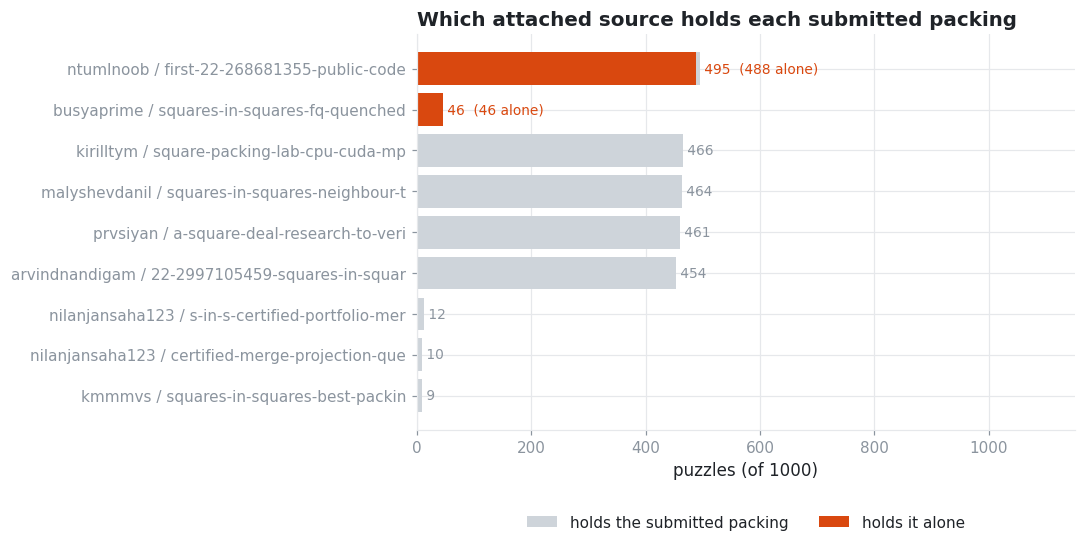

                                                              holds the best packing  and nobody else
ntumlnoob/first-22-268681355-public-code-with-explanation                        495              488
busyaprime/squares-in-squares-fq-quenched-packings                                46               46
kirilltym/square-packing-lab-cpu-cuda-mps                                        466                0
malyshevdanil/squares-in-squares-neighbour-transfer-squeeze                      464                0
prvsiyan/a-square-deal-research-to-verified-packings                             461                0
arvindnandigam/22-2997105459-squares-in-squares                                  454                0
nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench                      12                0
nilanjansaha123/certified-merge-projection-quench-gpu-screen                      10                0
kmmmvs/squares-in-squares-best-packings                                           

In [6]:
holders = Counter()
sole = Counter()
for n, b in win.items():
    s = cands[n][b[0]]["sources"]
    holders.update(s)
    if len(s) == 1:
        sole[next(iter(s))] += 1
tab = pd.DataFrame({"holds the best packing": pd.Series(holders), "and nobody else": pd.Series(sole)}).fillna(0).astype(int)
tab = tab.sort_values(["and nobody else", "holds the best packing"], ascending=False)

short = lambda ref: ref.split("/")[0] + " / " + ref.split("/")[-1][:30]
fig, ax = plt.subplots(figsize=(10, 0.42 * min(len(tab), 20) + 1.4))
top = tab.head(20)[::-1]
ax.barh([short(r) for r in top.index], top["holds the best packing"], color="#ced4da", label="holds the submitted packing")
ax.barh([short(r) for r in top.index], top["and nobody else"], color=ACCENT, label="holds it alone")
for i, (v, w) in enumerate(zip(top["and nobody else"], top["holds the best packing"])):
    ax.text(w, i, f" {w}" + (f"  ({v} alone)" if v else ""), va="center", color=ACCENT if v else MUTED, fontsize=9)
ax.set_title("Which attached source holds each submitted packing")
ax.set_xlabel("puzzles (of 1000)")
ax.set_xlim(0, 1150)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(); plt.show()
print(tab.to_string())

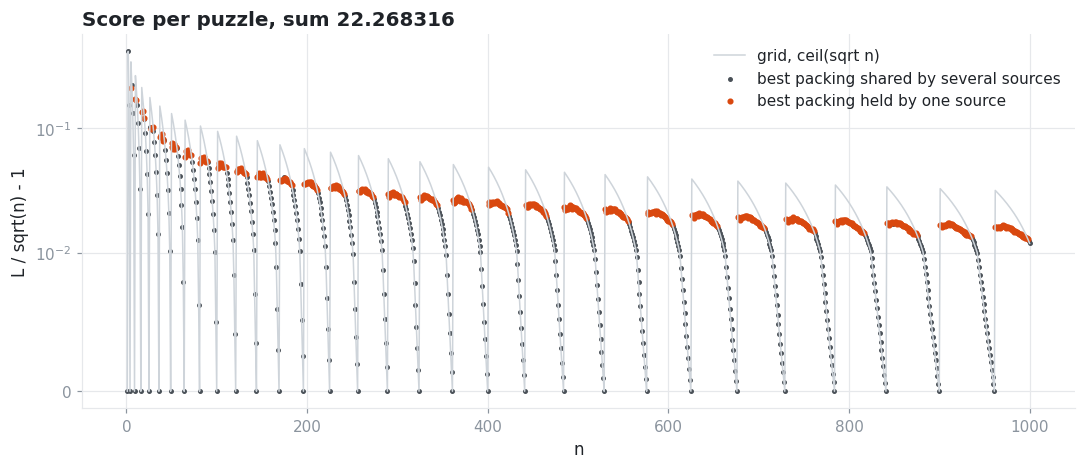

largest per-puzzle excess: n=2 0.4142, n=6 0.2247, n=5 0.2107, n=10 0.1723, n=11 0.1690, n=12 0.1547


In [7]:
ns = np.arange(1, 1001)
sc = np.array([win[n][1] if n in win else CEIL[n] for n in ns])
alone = np.array([n in win and len(cands[n][win[n][0]]["sources"]) == 1 for n in ns])
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(ns, [CEIL[n] for n in ns], color="#ced4da", lw=1.0, label="grid, ceil(sqrt n)")
ax.scatter(ns[~alone], sc[~alone], s=5, color="#495057", label="best packing shared by several sources")
ax.scatter(ns[alone], sc[alone], s=9, color=ACCENT, label="best packing held by one source")
ax.set_yscale("symlog", linthresh=0.01)
ax.set_xlabel("n"); ax.set_ylabel("L / sqrt(n) - 1")
ax.set_title(f"Score per puzzle, sum {sc.sum():.6f}")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
print("largest per-puzzle excess:", ", ".join(f"n={n} {sc[n-1]:.4f}" for n in ns[np.argsort(-sc)][:6]))

## 5. Against the best single public notebook

[ntumlnoob's First 22.268681355 Public Code](https://www.kaggle.com/code/ntumlnoob/first-22-268681355-public-code-with-explanation) is attached and certified with the same code. Puzzles where it holds
the same bytes as this notebook need no second check.

In [8]:
TOP_PUBLIC = {"ref": "ntumlnoob/first-22-268681355-public-code-with-explanation", "name": "ntumlnoob's First 22.268681355 Public Code", "lb": "22.268681355"}
# The best single public notebook as Kaggle displays it, certified with the same metric on the same packings.
def file_of(ref):
    hits = [(f, k) for f, k in file_keys.items() if source_of(Path(f)) == ref and Path(f).name == "submission.csv"]
    return min(hits, key=lambda h: len(Path(h[0]).parts)) if hits else (None, None)

ref_file, ref_keys = file_of(TOP_PUBLIC["ref"])
if ref_file is None:
    print("the top public notebook is not attached; comparison skipped")
else:
    ref_sc = {}
    todo = []
    for n in range(1, 1001):
        k = ref_keys.get(n)
        if k is None:
            ref_sc[n] = CEIL[n]
        elif n in win and k == win[n][0]:
            ref_sc[n] = win[n][1]                     # the same bytes: the same certified score
        else:
            todo.append((n, k))
    def cert(nk):
        n, k = nk
        _, s, _, reason = metric.evaluate_single_puzzle(n, rows_of(n, cands[n][k]["blob"]))
        return n, s, reason
    with mp.Pool(NPROC) as pool:
        for n, s, reason in pool.imap_unordered(cert, todo):
            ref_sc[n] = s
    ref_total = sum(ref_sc.values())
    # Selection gate against an independent file: no puzzle may come out worse than the top public notebook's.
    worse = [n for n in ref_sc if (win[n][1] if n in win else CEIL[n]) > ref_sc[n]]
    assert not worse, f"worse than the top public file on {worse[:10]}"
    gain = {n: ref_sc[n] - (win[n][1] if n in win else CEIL[n]) for n in range(1, 1001)}
    better = sorted((n for n in gain if gain[n] > 1e-12), key=lambda n: -gain[n])
    # Kaggle cuts the displayed score after 10 decimals (it does not round), so 12 are printed here.
    print(f"{TOP_PUBLIC['name']}: Kaggle displays {TOP_PUBLIC['lb']}, this metric gives {ref_total:.12f}")
    print(f"this notebook: {merged:.12f}, lower by {ref_total - merged:.3e} on {len(better)} puzzles")
    for n in better[:12]:
        print(f"  n={n:4d}  {ref_sc[n]:.8f} -> {win[n][1]:.8f}  ({', '.join(sorted(cands[n][win[n][0]]['sources']))[:70]})")

ntumlnoob's First 22.268681355 Public Code: Kaggle displays 22.268681355, this metric gives 22.268681355090
this notebook: 22.268315616923, lower by 3.657e-04 on 36 puzzles
  n= 927  0.01471304 -> 0.01455840  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 995  0.01332262 -> 0.01327426  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 860  0.01649892 -> 0.01645454  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 968  0.01627135 -> 0.01625283  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 867  0.01505401 -> 0.01503687  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 988  0.01430869 -> 0.01429327  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 808  0.01608207 -> 0.01606688  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 815  0.01469282 -> 0.01468075  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 926  0.01487737 -> 0.01486732  (busyaprime/squares-in-squares-fq-quenched-packings)
  n= 699  0.01740617 -> 0.

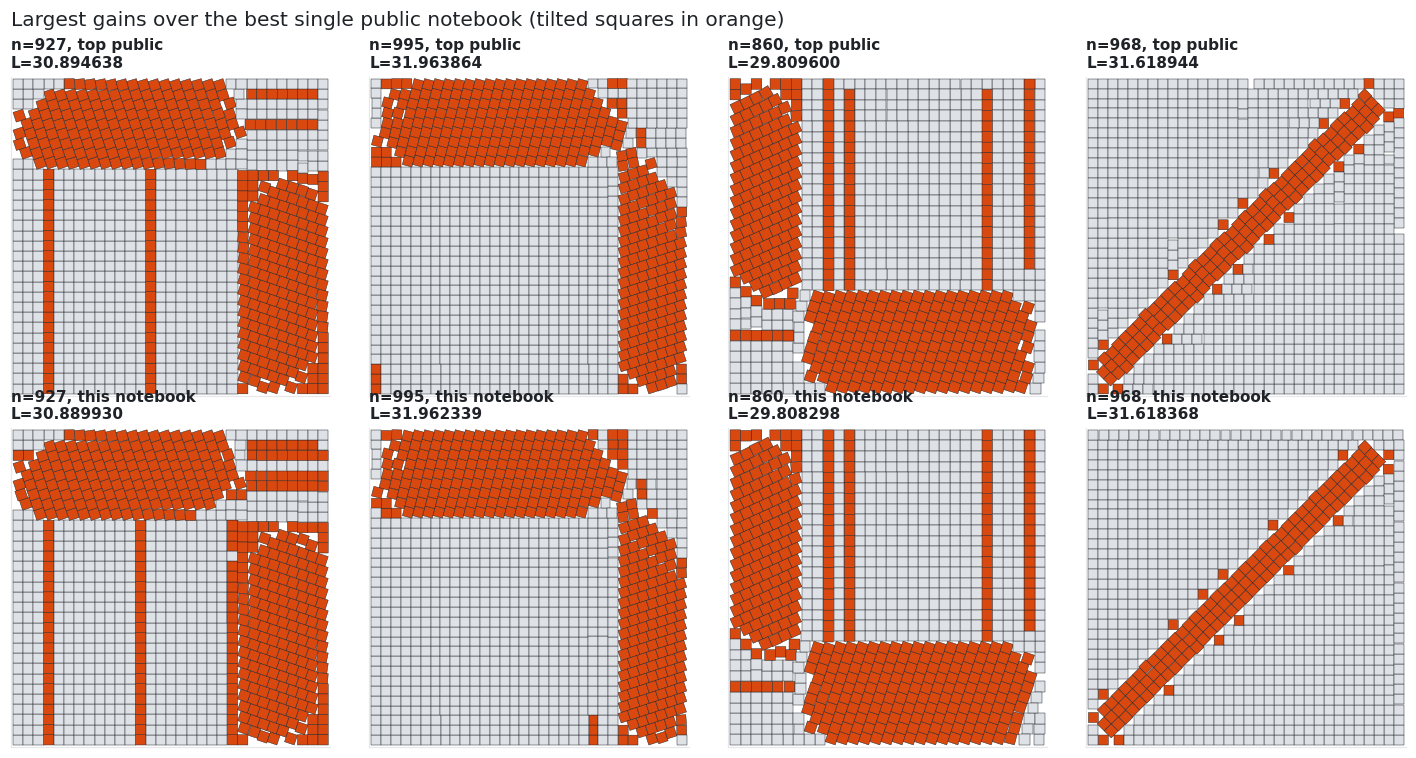

In [9]:
def polys(blob):
    a = np.array([[float(v) for v in line.split(",")[1:]] for line in blob.split("\n")])
    c, s = np.cos(a[:, 2]), np.sin(a[:, 2])
    base = np.array([[0.5, 0.5], [-0.5, 0.5], [-0.5, -0.5], [0.5, -0.5]])
    rot = np.stack([np.stack([c, -s], 1), np.stack([s, c], 1)], 1)       # (k, 2, 2)
    pts = np.einsum("kij,pj->kpi", rot, base) + a[:, None, :2]
    tilted = np.abs(((np.degrees(a[:, 2]) + 45) % 90) - 45) > 1e-6
    return pts, tilted

def draw(ax, n, key, title):
    pts, tilted = polys(cands[n][key]["blob"])
    pts = pts - pts.reshape(-1, 2).min(0)
    ax.add_collection(PolyCollection(pts, facecolors=np.where(tilted, ACCENT, "#dee2e6"), edgecolors=INK, linewidths=0.3))
    side = pts.reshape(-1, 2).max(0).max()
    ax.set_xlim(-0.2, side + 0.2); ax.set_ylim(-0.2, side + 0.2); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title, fontsize=10)

show = [n for n in better if n in ref_keys][:4] if ref_file is not None else []
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(3.3 * len(show), 7))
    axes = np.array(axes).reshape(2, -1)
    for j, n in enumerate(show):
        draw(axes[0, j], n, ref_keys[n], f"n={n}, top public\nL={ref_sc[n] * math.sqrt(n) + math.sqrt(n):.6f}")
        draw(axes[1, j], n, win[n][0], f"n={n}, this notebook\nL={win[n][1] * math.sqrt(n) + math.sqrt(n):.6f}")
    plt.suptitle("Largest gains over the best single public notebook (tilted squares in orange)", x=0.02, ha="left")
    plt.tight_layout(); plt.show()

## 6. Our packings: one fq quench of every tilted puzzle

`fq quench` is the quench and polish engine of Evan Daniel's
[square-packing](https://github.com/evand/square-packing) (Rust, MIT license, commit 6067db5): an augmented-Lagrangian
squeeze of the container side followed by a sequential LP polish over centres and angles. We built it unchanged and
called it through the repository's own `hop.quench` wrapper, once per puzzle, on the 547 puzzles whose best
public packing is shorter than the grid, from that packing, with the repository's default flags (`--loosen 1.02`).
Total 2.5 hours of single-process time on a laptop. We also ran kirilltym's contact LP polish (adapted from
lightningv08, Apache 2.0) on every tilted puzzle; its largest gain is 1.3e-7. A shorter packing of n also
shortens n + 2 floor(L) + 1 by the width-1 border rule (the strip is placed 1e-13 clear of the packing, from its
bounding box at 60 digits), so the border rule ran once more on the new sides.

46 puzzles came out shorter and pass the hosts' metric, 3.7e-4 in total:

| n | best public L | this notebook L | gain in score | how |
|---:|---:|---:|---:|---|
| 927 | 30.894637782 | 30.889929605 | 1.5e-4 | fq quench |
| 995 | 31.963864355 | 31.962338691 | 4.8e-5 | fq quench |
| 860 | 29.809600015 | 29.808298462 | 4.4e-5 | fq quench |
| 968 | 31.618944010 | 31.618367919 | 1.9e-5 | width-1 border |
| 867 | 29.888126981 | 29.887622284 | 1.7e-5 | fq quench |
| 988 | 31.882224700 | 31.881739952 | 1.5e-5 | fq quench |
| 808 | 28.882479100 | 28.882047431 | 1.5e-5 | fq quench |
| 815 | 28.967658529 | 28.967314016 | 1.2e-5 | fq quench |
| 926 | 30.882970187 | 30.882664366 | 1.0e-5 | fq quench |
| 699 | 26.898803038 | 26.898602975 | 7.6e-6 | fq quench |
| 602 | 24.976925773 | 24.976776931 | 6.1e-6 | fq quench |
| 934 | 30.978222650 | 30.978068720 | 5.0e-6 | fq quench |
| 923 | 30.849555586 | 30.849437140 | 3.9e-6 | fq quench |
| 704 | 26.963383501 | 26.963308642 | 2.8e-6 | fq quench |
| 916 | 30.762284805 | 30.762211299 | 2.4e-6 | fq quench |
| 984 | 31.839051337 | 31.839022230 | 9.3e-7 | fq quench |
| 759 | 27.971621729 | 27.971608605 | 4.8e-7 | fq quench |
| 933 | 30.971447367 | 30.971439583 | 2.5e-7 | fq quench |
| 997 | 31.990602886 | 31.990597428 | 1.7e-7 | fq quench |
| 736 | 27.638988482 | 27.638984967 | 1.3e-7 | contact LP polish |
| 597 | 24.897735938 | 24.897734279 | 6.8e-8 | fq quench |
| 866 | 29.882640839 | 29.882639435 | 4.8e-8 | fq quench |
| 799 | 28.766832803 | 28.766832033 | 2.7e-8 | fq quench |
| 807 | 28.870809661 | 28.870809145 | 1.8e-8 | fq quench |
| 547 | 23.869752775 | 23.869752475 | 1.3e-8 | contact LP polish |
| 987 | 31.870936218 | 31.870936053 | 5.3e-9 | fq quench |
| 446 | 21.638533459 | 21.638533356 | 4.9e-9 | width-1 border |
| 917 | 30.771007692 | 30.771007654 | 1.3e-9 | fq quench |
| 806 | 28.859713046 | 28.859713017 | 1.0e-9 | contact LP polish |
| 591 | 24.817351463 | 24.817351442 | 8.6e-10 | contact LP polish |
| 648 | 25.908751679 | 25.908751659 | 8.0e-10 | fq quench |
| 977 | 31.753030382 | 31.753030366 | 5.0e-10 | contact LP polish |
| 595 | 24.871333380 | 24.871333371 | 3.8e-10 | contact LP polish |
| 504 | 22.915192428 | 22.915192421 | 3.2e-10 | fq quench |
| 809 | 28.893193572 | 28.893193567 | 1.6e-10 | fq quench |
| 700 | 26.907569197 | 26.907569197 | 1.1e-11 | fq quench |
| 580 | 24.583782191 | 24.583782191 | 4.1e-13 | width-1 border |
| 629 | 25.583782191 | 25.583782191 | 3.9e-13 | width-1 border |
| 905 | 30.583782191 | 30.583782191 | 3.3e-13 | width-1 border |
| 966 | 31.583782191 | 31.583782191 | 3.2e-13 | width-1 border |
| 329 | 18.656854249 | 18.656854249 | 1.9e-13 | width-1 border |
| 332 | 18.740417288 | 18.740417288 | 1.9e-13 | width-1 border |
| 677 | 26.520815280 | 26.520815280 | 1.9e-13 | width-1 border |
| 325 | 18.535533906 | 18.535533906 | 1.8e-13 | width-1 border |
| 326 | 18.535533906 | 18.535533906 | 1.8e-13 | width-1 border |
| 908 | 30.638533588 | 30.638533588 | 3.0e-14 | width-1 border |

Most public packings are already at a quench minimum: the quench moved 31 of 547 (some by
under 1e-12), and 19 of the 28 accepted quench gains have n of 800 or more. The
dataset holds only these 46 packings, the three scripts (`33_hop.py`, `33_polish.py`, `33_border.py`) and the
quench log.

## 7. Does the metric copy agree with Kaggle?

Run locally before this version, on each public notebook's own `submission.csv` as downloaded with
`kaggle kernels output` on 2026-10-27, against the score Kaggle displays for it (Code tab, read 2026-10-27 22:40 UTC). A
notebook re-run after the read can differ.

| notebook | Kaggle displays | metric copy, its submission.csv | difference |
|---|---:|---:|---:|
| [First 22.268681355 Public Code With Explanation](https://www.kaggle.com/code/ntumlnoob/first-22-268681355-public-code-with-explanation) | 22.268681355 | 22.268681355090 | 9.0e-11 |
| [Squares in Squares:Top LB Blending + Visualization](https://www.kaggle.com/code/aqibrazadev/squares-in-squares-top-lb-blending-visualization) | 22.2850511253 | 22.298230720554 | 1.3e-2 |
| [Squares in Squares / Neighbour Transfer + Squeeze](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-neighbour-transfer-squeeze) | 22.2850511255 | 22.285051125530 | 3.0e-11 |
| [S in S / Certified Portfolio Merge + Proj Quench](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench) | 22.2850716747 | 22.285091341508 | 2.0e-5 |
| [Certified Merge + CUDA Rectangular Cycles](https://www.kaggle.com/code/avazaku/certified-merge-cuda-rectangular-cycles) | 22.2850716747 | 22.285071674730 | 3.0e-11 |
| [Certified Merge + Projection Quench + GPU Screen](https://www.kaggle.com/code/nilanjansaha123/certified-merge-projection-quench-gpu-screen) | 22.2850725074 | 22.285072507467 | 6.7e-11 |
| [Square Packing Lab / CPU/CUDA/MPS](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps) | 22.2851309952 | 22.285130995271 | 7.1e-11 |
| [🧩 Squares in Squares / Deep EDA & Analogies](https://www.kaggle.com/code/evgendvorkin/squares-in-squares-deep-eda-analogies) | 22.2851311871 | 22.285131187174 | 7.4e-11 |
| [A Square Deal / Research to Verified Packings](https://www.kaggle.com/code/prvsiyan/a-square-deal-research-to-verified-packings) | 22.2869976416 | 22.286997641624 | 2.4e-11 |
| [Squares 101: the Starter Kit (2,600+ downloads)](https://www.kaggle.com/code/alexchilton/squares-101-the-starter-kit-2-600-downloads) | 22.2869976416 | 22.286997641624 | 2.4e-11 |
| [Fault-line DP + Basin Hopping - LB 22.2990](https://www.kaggle.com/code/alexchilton/fault-line-dp-basin-hopping-lb-22-2990) | 22.2890148608 | 22.289014860818 | 1.8e-11 |
| [S in S / Certified Portfolio Merge + Proj Quench2](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench2) | 22.295875429 | 22.295875429070 | 7.0e-11 |
| [Squares Certified Portfolio Blend](https://www.kaggle.com/code/octaviograu/squares-certified-portfolio-blend) | 22.2967859198 | 22.296785919847 | 4.7e-11 |
| [Auto-updater](https://www.kaggle.com/code/prvsiyan/auto-updater) | 22.2972606486 | 22.297260648607 | 7.4e-12 |
| [🐈‍⬛ Think. Select. Reclose](https://www.kaggle.com/code/lucifer19/think-select-reclose) | 22.298303135 | 22.295914898798 | -2.4e-3 |
| [Squares in Squares / CPU/CUDA/MPS / EDA+ProjUnion](https://www.kaggle.com/code/rushikeshpundkar/squares-in-squares-cpu-cuda-mps-eda-projunion) | 22.2987585105 | 22.298758510576 | 7.6e-11 |
| [1000 Puzzles - Ensemble [LB 22.298819]](https://www.kaggle.com/code/seshurajup/1000-puzzles-ensemble-lb-22-298819) | 22.298818753 | 22.298169548953 | -6.5e-4 |
| [Squares in Squares: Geometric Optimization](https://www.kaggle.com/code/ujjwalupreti/squares-in-squares-geometric-optimization) | 22.299955713 | 22.299955713039 | 3.9e-11 |
| [Squares in Squares / CUDA Packing Search](https://www.kaggle.com/code/lightningv08/squares-in-squares-cuda-packing-search) | 22.303399758 | 22.303399758060 | 6.0e-11 |

Kaggle cuts the displayed score after 10 decimals instead of rounding it, so a difference between 0 and 1e-10 is exact agreement. The 4 rows outside that band are notebooks whose newest output is not the version their author submitted: Kaggle shows the score of the submitted version.

Public submission files that contain packings the metric rejects (each rejected puzzle is charged
`ceil(sqrt(n))/sqrt(n) - 1`):

| file | puzzles rejected | its score with them charged the grid |
|---|---:|---:|
| [avikdas567/optimal-packing-of-n-unit-squares-sat-dynamics](https://www.kaggle.com/code/avikdas567/optimal-packing-of-n-unit-squares-sat-dynamics), `submission.csv` | 5 | 25.869391 |
| [zkskhurram/kaggle-squares-in-squares](https://www.kaggle.com/code/zkskhurram/kaggle-squares-in-squares), `kaggle_upload_package/submission.csv` | 1 | 28.937670 |
| [zkskhurram/kaggle-squares-in-squares](https://www.kaggle.com/code/zkskhurram/kaggle-squares-in-squares), `submission.csv` | 1 | 28.937670 |

## 8. What every public notebook does

All 70 public notebooks of the competition, read on 2026-10-27: source, metadata and run log. "Best
packings held" counts the puzzles where that notebook's output holds the packing this notebook submits (shared or
alone). Kaggle score is shown where the Code tab displayed it at the read.

| notebook | votes | Kaggle score | kind | what it does | best packings held |
|---|---:|---:|---|---|---:|
| [Squares in Squares - Per-Puzzle Leaderboard](https://www.kaggle.com/code/inversion/squares-in-squares-per-puzzle-leaderboard) | 73 |  | eda | interactive HTML table |  |
| [Square Packing Lab / CPU/CUDA/MPS](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps) | 61 | 22.2851309952 | optimizer+merge | whole-packing portfolio union, SAT separation repair, fixed-angle LP axis reclosure | 467 |
| [Squares in Squares / CUDA Packing Search](https://www.kaggle.com/code/lightningv08/squares-in-squares-cuda-packing-search) | 57 | 22.303399758 | optimizer+merge | CUDA multi-start SAT proposals, LP feasibility restoration, staircase/fault-line DP composition |  |
| [Squares in Squares / Neighbour Transfer + Squeeze](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-neighbour-transfer-squeeze) | 46 | 22.2850511255 | optimizer+merge | certified merge, CUDA L-BFGS SAT-penalty squeeze, trust-region sequential LP | 467 |
| [Squares 101: the Starter Kit (2,600+ downloads)](https://www.kaggle.com/code/alexchilton/squares-101-the-starter-kit-2-600-downloads) | 35 | 22.2869976416 | baseline | float64 round-trip certification, certified best-known packings, tilted n=5 construction | 465 |
| [S in S / Certified Portfolio Merge + Proj Quench](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench) | 29 | 22.2850716747 | optimizer+merge | certified merge, SAT-penalty projection quench, free constructions | 14 |
| [Squares in Squares: FTMC & MILP Refill (22.311)](https://www.kaggle.com/code/cdeotte/squares-in-squares-ftmc-milp-refill-22-311) | 27 |  | optimizer | FTMC tilted-core mutation, MILP refill (fill_rect), 4D fault-line DP |  |
| [Squares in Squares / Visual EDA, Metric & Gallery](https://www.kaggle.com/code/cdeotte/squares-in-squares-visual-eda-metric-gallery) | 25 |  | eda | metric reimplementation, SAT + interval arithmetic, packing gallery |  |
| [🧩 Squares in Squares / Deep EDA & Analogies](https://www.kaggle.com/code/evgendvorkin/squares-in-squares-deep-eda-analogies) | 23 | 22.2851311871 | eda | SAT with KD-tree, 45-degree courtyard construction, bounded discrete search | 467 |
| [Squares in Squares:Top LB Blending + Visualization](https://www.kaggle.com/code/aqibrazadev/squares-in-squares-top-lb-blending-visualization) | 21 | 22.2850511253 | merge | per-n best-of blend, vectorized SAT overlap check, visualization | 467 |
| [Auto-updater](https://www.kaggle.com/code/prvsiyan/auto-updater) | 19 | 22.2972606486 | merge | per-n witness overlay on public baseline, overlap check | 5 |
| [Squares in Sq: Intuition is Not Enough](https://www.kaggle.com/code/mpwolke/squares-in-sq-intuition-is-not-enough) | 18 |  | eda | sample submission summary, plotly scatter |  |
| [Fault-line DP + Basin Hopping - LB 22.2990](https://www.kaggle.com/code/alexchilton/fault-line-dp-basin-hopping-lb-22-2990) | 16 | 22.2890148608 | optimizer+merge | certified merge, Couzo exact witnesses, basin hopping (evand Rust packer) | 465 |
| [Optimal Packing of N Unit Squares: SAT & Dynamics](https://www.kaggle.com/code/avikdas567/optimal-packing-of-n-unit-squares-sat-dynamics) | 16 |  | baseline | SAT overlap check, catalogued literature packings, centroid dilation 1e-7 | 453 |
| [22.3856 / CPU/CUDA/MPS / EDA+Seam LP](https://www.kaggle.com/code/kirilltym/22-3856-cpu-cuda-mps-eda-seam-lp) | 16 |  | optimizer+merge | seam LP, alternating contact refinement, axis reclosure |  |
| [Squares in Squares / Multi-Gadget Fault DP [22.48]](https://www.kaggle.com/code/cdeotte/squares-in-squares-multi-gadget-fault-dp-22-48) | 15 |  | optimizer | 4D fault-line DP, order-statistic gadget extraction, anti-diagonal fault composition |  |
| [1000 Puzzles - Ensemble [LB 22.298819]](https://www.kaggle.com/code/seshurajup/1000-puzzles-ensemble-lb-22-298819) | 15 | 22.298818753 | fork | copy of ensemble output, viewer | 467 |
| [Squares in Squares / Ensemble [22.376]](https://www.kaggle.com/code/cdeotte/squares-in-squares-ensemble-22-376) | 14 |  | merge | embedded lzma/base64 payload, integer-scaled coordinates, cKDTree verify |  |
| [A Square Deal / Research to Verified Packings](https://www.kaggle.com/code/prvsiyan/a-square-deal-research-to-verified-packings) | 13 | 22.2869976416 | merge | per-n merge, official metric check per puzzle, self-feeding live baseline | 465 |
| [Squarecraft / Beyond the Grid / 22.7417 LB](https://www.kaggle.com/code/avazaku/squarecraft-beyond-the-grid-22-7417-lb) | 11 |  | optimizer | Squares Project seeds (n<=324), trim and outer-L extension, Gobel families |  |
| [Squares in Squares - Baseline Pipeline](https://www.kaggle.com/code/arunsworkspace/squares-in-squares-baseline-pipeline) | 9 |  | baseline | grid baseline, simulated annealing, SAT validator | 453 |
| [Subset transfer, contact refinement and compaction](https://www.kaggle.com/code/kozykappa/subset-transfer-contact-refinement-and-compaction) | 9 |  | optimizer+merge | subset transfer (n+k to n), contact refinement, uniform centre compaction |  |
| [🐈‍⬛ Think. Select. Reclose](https://www.kaggle.com/code/lucifer19/think-select-reclose) | 8 | 22.298303135 | merge | whole-puzzle selection, official metric promotion gate, rollback | 463 |
| [Certified Merge + Projection Quench + GPU Screen](https://www.kaggle.com/code/nilanjansaha123/certified-merge-projection-quench-gpu-screen) | 8 | 22.2850725074 | optimizer+merge | certified merge, free constructions, projection quench | 14 |
| [Certified Merge + CUDA Rectangular Cycles](https://www.kaggle.com/code/avazaku/certified-merge-cuda-rectangular-cycles) | 8 | 22.2850716747 | optimizer+merge | certified merge on Nilanjan Saha V4, CUDA rectangular breathing cycles, paired rectangular vs isotropic arms | 14 |
| [Squares in Squares Fault-DP & Contact LP](https://www.kaggle.com/code/robinamirbahar/squares-in-squares-fault-dp-contact-lp) | 6 |  | eda | contact LP squeeze demo, SAT verifier, n=5 tilted gadget |  |
| [Santa 2025 to Squares in Squares: What Transfers](https://www.kaggle.com/code/skarin/santa-2025-to-squares-in-squares-what-transfers) | 6 |  | eda | closed-form square penetration, deletion and frame monotonicity closure, official metric certification | 3 |
| [S in S / Certified Portfolio Merge + Proj Quench2](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench2) | 5 | 22.295875429 | optimizer+merge | certified merge with official metric, deletion and border expansion, SAT penalty energy L-BFGS | 10 |
| [Certified Witnesses + Basin Hopping - LB 22.3084](https://www.kaggle.com/code/alexchilton/certified-witnesses-basin-hopping-lb-22-3084) | 4 |  | optimizer+merge | certified merge, Couzo exact witnesses import, basin hopping (evand Rust packer) | 461 |
| [Squarecraft II / Unjam the Grid / 22.408597 LB](https://www.kaggle.com/code/avazaku/squarecraft-ii-unjam-the-grid-22-408597-lb) | 4 |  | optimizer+merge | MILP contact-axis switching (HiGHS), LP compaction, contact polish |  |
| [22.3073 LB / Square Packing: Seam Surgery](https://www.kaggle.com/code/avazaku/22-3073-lb-square-packing-seam-surgery) | 4 |  | optimizer+merge | dual-guided contact-axis MILP, sparse LP compaction, L-border witness transfer | 461 |
| [Squares Certified Portfolio Blend](https://www.kaggle.com/code/octaviograu/squares-certified-portfolio-blend) | 3 | 22.2967859198 | optimizer+merge | certified merge, mpmath interval SAT certificate, sparse contact LP | 463 |
| [Three square packings that beat the records](https://www.kaggle.com/code/pjmathematician/three-square-packings-that-beat-the-records) | 3 |  | other | hand-listed packings, pairwise separation verification |  |
| [Squares in Squares: Exact Validator, Record Merge](https://www.kaggle.com/code/dariushafshar/squares-in-squares-exact-validator-record-merge) | 3 |  | merge | exact metric mirror (float64 SAT + mpmath interval), Couzo certificate recipes, certified merge | 453 |
| [Squares in Squares / Getting Started](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-getting-started) | 3 |  | baseline | ceil(sqrt n) grid, local metric validation | 453 |
| [📐 Kaggle: Squares in Squares](https://www.kaggle.com/code/zkskhurram/kaggle-squares-in-squares) | 3 |  | baseline | known small-n constructions, SAT check, grid | 453 |
| [Did the Patch Help? An LP Ablation Audit](https://www.kaggle.com/code/yangkuangou/did-the-patch-help-an-lp-ablation-audit) | 3 |  | other | LP ablation, fixed-angle LP polish |  |
| [TestSquares in Squares / Ensemble [22.376]](https://www.kaggle.com/code/mtoshidesu/testsquares-in-squares-ensemble-22-376) | 3 |  | optimizer+merge | embedded layout bank (Base85/XZ), SAT safety gate, fixed-angle sparse LP |  |
| [Squares  in Squares 2](https://www.kaggle.com/code/chaitanyajamble/squares-in-squares-2) | 3 |  | optimizer | move-bucket local search (compress, contact, delete, fault, hinge, jitter), LP fixed-contact polish, certify | 453 |
| [First 22.268681355 Public Code With Explanation](https://www.kaggle.com/code/ntumlnoob/first-22-268681355-public-code-with-explanation) | 3 | 22.268681355 | portfolio export | frozen private portfolio export, rectangle assembly + CPU FTMC/FQ + GPU L-BFGS (archived traces), hash-bound metric receipts | 954 |
| [notebook87513fb5d4](https://www.kaggle.com/code/janiogomesribeiro/notebook87513fb5d4) | 2 |  | merge | certified merge, SAT feasibility check | 461 |
| [Squares in Squares v1](https://www.kaggle.com/code/mirzamilanfarabi/squares-in-squares-v1) | 2 |  | baseline | grid baseline, numba local search | 453 |
| [22.3043 LB / Square Packing with Tilt Engine](https://www.kaggle.com/code/avazaku/22-3043-lb-square-packing-with-tilt-engine) | 2 |  | optimizer | coherent rigid-block sparse LP, free-angle polish, coherent switch discrete search | 461 |
| [Squares in Squares v2](https://www.kaggle.com/code/mirzamilanfarabi/squares-in-squares-v2) | 2 |  | optimizer | alternating reclosure, grid comparison | 458 |
| [Certified Merge of Public Packings - LB 22.5978](https://www.kaggle.com/code/alexchilton/certified-merge-of-public-packings-lb-22-5978) | 2 |  | merge | per-n best-of merge, certified merge, official metric check | 455 |
| [Squares_in_Squares_Baseline](https://www.kaggle.com/code/koushikkumardinda/squares-in-squares-baseline) | 2 |  | baseline | constructive packings, mpmath interval pair certification | 453 |
| [Squares in Squares / Fresh Records, Certified](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-fresh-records-certified) | 2 |  | merge | certified merge, Couzo exact certificates (commit 6b7391d), border expansion | 453 |
| [Squares_Baseline_Merge_Best_v2](https://www.kaggle.com/code/yuki16/squares-baseline-merge-best-v2) | 2 |  | optimizer | SAT overlap check, diagonal-band family, penalty simulated annealing | 453 |
| [Squares Workbench: Choose a Patch, Test a Shrink](https://www.kaggle.com/code/yangkuangou/squares-workbench-choose-a-patch-test-a-shrink) | 2 |  | optimizer | angle-threshold snap reclosure, fixed-angle LP reclosure, official proof export |  |
| [Mind the Gap: Plan Your Next Packing Update](https://www.kaggle.com/code/yangkuangou/mind-the-gap-plan-your-next-packing-update) | 1 |  | tooling | per-puzzle gap accounting, reference table join |  |
| [Squares in Squares: D4 Seam DP Dual GPU LBFGS](https://www.kaggle.com/code/jiwasawa/squares-in-squares-d4-seam-dp-dual-gpu-lbfgs) | 1 |  | optimizer | D4 seam-profile DP, dual-GPU L-BFGS basin hopping, separation-graph LP |  |
| [New Record, Same Optimum: Audit the Last Decimal](https://www.kaggle.com/code/yangkuangou/new-record-same-optimum-audit-the-last-decimal) | 1 |  | eda | record-claim audit |  |
| [Fewer Inputs: Prune an Ensemble by Score Loss](https://www.kaggle.com/code/yangkuangou/fewer-inputs-prune-an-ensemble-by-score-loss) | 1 |  | tooling | leave-one-out removal loss, greedy source pruning |  |
| [Squares in Squares / Neighbour Transfer + Squeeze](https://www.kaggle.com/code/ridhamkavani/squares-in-squares-neighbour-transfer-squeeze) | 1 |  | fork | certified merge, CUDA L-BFGS SAT-penalty squeeze, trust-region sequential LP | 461 |
| [Validate the Delta: Reuse Unchanged Packing Checks](https://www.kaggle.com/code/yangkuangou/validate-the-delta-reuse-unchanged-packing-checks) | 1 |  | tooling | incremental (delta) validation, LP ablation audit |  |
| [Squares in Squares Score 22.298 Gallery](https://www.kaggle.com/code/prvsiyan/squares-in-squares-score-22-298-gallery) | 1 |  | eda | Shapely validation, SHA-256 provenance, visual gallery |  |
| [SiS 02 / Records + Ensemble](https://www.kaggle.com/code/leonidkononenko/sis-02-records-ensemble) | 0 |  | merge | published record packings (Friedman/Ellsworth catalogue), subset transfer from larger packings, certified merge | 453 |
| [1000 Puzzles - Ensemble [LB 22.298819]](https://www.kaggle.com/code/rushikeshpundkar/1000-puzzles-ensemble-lb-22-298819) | 0 |  | merge | best-per-n merge of attached notebook outputs | 453 |
| [SiS 03 / Record Hunt Optimizer](https://www.kaggle.com/code/leonidkononenko/sis-03-record-hunt-optimizer) | 0 |  | optimizer | GPU batch annealing, penalty compaction (Adam), target selection by excess over rolling envelope | 453 |
| [Squares in Squares / CPU/CUDA/MPS / EDA+ProjUnion](https://www.kaggle.com/code/rushikeshpundkar/squares-in-squares-cpu-cuda-mps-eda-projunion) | 0 | 22.2987585105 | optimizer+merge | projected union of witnesses, local hinge refinement, contact polish | 461 |
| [SiS 01 / Baseline + Validator](https://www.kaggle.com/code/leonidkononenko/sis-01-baseline-validator) | 0 |  | baseline | numba validator, classical constructions, merge and propagation | 453 |
| [Qwen3 Agent](https://www.kaggle.com/code/mirzamilanfarabi/qwen3-agent) | 0 |  | other | LLM agent with Python REPL, deterministic fallback | 453 |
| [Squares / CUDA Contact Release + SAT + LP](https://www.kaggle.com/code/avazaku/squares-cuda-contact-release-sat-lp) | 0 |  | optimizer+merge | certified merge, CUDA rectangular breathing, SAT overlap relaxation |  |
| [Improved Notebook](https://www.kaggle.com/code/nilanjansaha123/improved-notebook) | 0 |  | optimizer+merge | frontier merge, angle-band snapping, coupled center-angle SLP | 8 |
| [squares-in-squares](https://www.kaggle.com/code/ranaharshiddh/squares-in-squares) | 0 |  | other |  |  |
| [Squares in Squares: Geometric Optimization](https://www.kaggle.com/code/ujjwalupreti/squares-in-squares-geometric-optimization) | 0 | 22.299955713 | optimizer | SAT validation, contact LP squeeze (HiGHS), grid fallback | 461 |
| [INOS v0.6 K.MOSH Squares in Squares (22.366222)](https://www.kaggle.com/code/kyleluecke/inos-v0-6-k-mosh-squares-in-squares-22-366222) | 0 |  | other | iterated LP (claimed, closed source) |  |
| [Squares in Squares](https://www.kaggle.com/code/chaitanyajamble/squares-in-squares) | 0 |  | baseline | axis-aligned grid | 453 |
| [notebooksquare](https://www.kaggle.com/code/soumikkaran/notebooksquare) | 0 |  | baseline | grid |  |

In [10]:
prov = pd.DataFrame([{"n": n, "score": win[n][1], "L": win[n][3], "sources": "; ".join(sorted(cands[n][win[n][0]]["sources"]))}
                     for n in sorted(win)])
prov.to_csv("provenance.csv", index=False)
print(f"provenance.csv: {len(prov)} rows; total runtime {time.time() - T0:.0f}s")
prov.head(12)

provenance.csv: 1000 rows; total runtime 1180s


,n,score,L,sources
0,1,0.000000,1.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
1,2,0.414214,2.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
2,3,0.154701,2.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
3,4,0.000000,2.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
4,5,0.210655,2.70710678118654756220042218105243000000000000...,ntumlnoob/first-22-268681355-public-code-with-...
5,6,0.224745,3.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
6,7,0.133893,3.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
7,8,0.060660,3.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
8,9,0.000000,3.00000000000000000000000000000000000000000000...,arvindnandigam/22-2997105459-squares-in-square...
9,10,0.172290,3.70710678118654760000000000000000000000000000...,ntumlnoob/first-22-268681355-public-code-with-...


## Credits

Every packing in `submission.csv` was found and published by the authors below, except the 46 of section 6, which are their public packings after one quench by Evan Daniel's `fq` ([square-packing](https://github.com/evand/square-packing), MIT), kirilltym's contact LP polish or the width-1 border rule, run by us. Counts are puzzles where the source holds the submitted packing (shared or alone), from the local run before this version.

- [ntumlnoob/first-22-268681355-public-code-with-explanation](https://www.kaggle.com/code/ntumlnoob/first-22-268681355-public-code-with-explanation): 954 puzzles, 487 of them alone
- [evgendvorkin/squares-in-squares-deep-eda-analogies](https://www.kaggle.com/code/evgendvorkin/squares-in-squares-deep-eda-analogies): 467 puzzles
- [kirilltym/square-packing-lab-cpu-cuda-mps](https://www.kaggle.com/code/kirilltym/square-packing-lab-cpu-cuda-mps): 467 puzzles
- [malyshevdanil/squares-in-squares-neighbour-transfer-squeeze](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-neighbour-transfer-squeeze): 467 puzzles
- [kmmmvs/squares-in-squares-best-packings](https://www.kaggle.com/datasets/kmmmvs/squares-in-squares-best-packings): 467 puzzles
- [aqibrazadev/squares-in-squares-top-lb-blending-visualization](https://www.kaggle.com/code/aqibrazadev/squares-in-squares-top-lb-blending-visualization): 467 puzzles
- [seshurajup/1000-puzzles-ensemble-lb-22-298819](https://www.kaggle.com/code/seshurajup/1000-puzzles-ensemble-lb-22-298819): 467 puzzles
- [prvsiyan/a-square-deal-research-to-verified-packings](https://www.kaggle.com/code/prvsiyan/a-square-deal-research-to-verified-packings): 465 puzzles
- [alexchilton/fault-line-dp-basin-hopping-lb-22-2990](https://www.kaggle.com/code/alexchilton/fault-line-dp-basin-hopping-lb-22-2990): 465 puzzles
- [alexchilton/squares-in-squares-starter-kit](https://www.kaggle.com/datasets/alexchilton/squares-in-squares-starter-kit): 465 puzzles
- [alexchilton/squares-101-the-starter-kit-2-600-downloads](https://www.kaggle.com/code/alexchilton/squares-101-the-starter-kit-2-600-downloads): 465 puzzles
- [octaviograu/squares-certified-blend-inputs](https://www.kaggle.com/datasets/octaviograu/squares-certified-blend-inputs): 463 puzzles
- [lucifer19/think-select-reclose](https://www.kaggle.com/code/lucifer19/think-select-reclose): 463 puzzles
- [octaviograu/squares-certified-portfolio-blend](https://www.kaggle.com/code/octaviograu/squares-certified-portfolio-blend): 463 puzzles
- [avazaku/22-3043-lb-square-packing-with-tilt-engine](https://www.kaggle.com/code/avazaku/22-3043-lb-square-packing-with-tilt-engine): 461 puzzles
- [ujjwalupreti/squares-in-squares-geometric-optimization](https://www.kaggle.com/code/ujjwalupreti/squares-in-squares-geometric-optimization): 461 puzzles
- [lucifer19/think-pack-ship-transparent-inputs](https://www.kaggle.com/datasets/lucifer19/think-pack-ship-transparent-inputs): 461 puzzles
- [arvindnandigam/22-2997105459-squares-in-squares](https://www.kaggle.com/datasets/arvindnandigam/22-2997105459-squares-in-squares): 461 puzzles
- [ridhamkavani/squares-in-squares-neighbour-transfer-squeeze](https://www.kaggle.com/code/ridhamkavani/squares-in-squares-neighbour-transfer-squeeze): 461 puzzles
- [alexchilton/certified-witnesses-basin-hopping-lb-22-3084](https://www.kaggle.com/code/alexchilton/certified-witnesses-basin-hopping-lb-22-3084): 461 puzzles
- [avazaku/22-3073-lb-square-packing-seam-surgery](https://www.kaggle.com/code/avazaku/22-3073-lb-square-packing-seam-surgery): 461 puzzles
- [rushikeshpundkar/squares-in-squares-cpu-cuda-mps-eda-projunion](https://www.kaggle.com/code/rushikeshpundkar/squares-in-squares-cpu-cuda-mps-eda-projunion): 461 puzzles
- [janiogomesribeiro/notebook87513fb5d4](https://www.kaggle.com/code/janiogomesribeiro/notebook87513fb5d4): 461 puzzles
- [mirzamilanfarabi/squares-in-squares-v2](https://www.kaggle.com/code/mirzamilanfarabi/squares-in-squares-v2): 458 puzzles
- [alexchilton/certified-merge-of-public-packings-lb-22-5978](https://www.kaggle.com/code/alexchilton/certified-merge-of-public-packings-lb-22-5978): 455 puzzles
- [dariushafshar/squares-in-squares-certified-packings](https://www.kaggle.com/datasets/dariushafshar/squares-in-squares-certified-packings): 453 puzzles
- [arunsworkspace/squares-in-squares-baseline-pipeline](https://www.kaggle.com/code/arunsworkspace/squares-in-squares-baseline-pipeline): 453 puzzles
- [malyshevdanil/squares-in-squares-getting-started](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-getting-started): 453 puzzles
- [malyshevdanil/squares-in-squares-fresh-records-certified](https://www.kaggle.com/code/malyshevdanil/squares-in-squares-fresh-records-certified): 453 puzzles
- [dariushafshar/squares-in-squares-exact-validator-record-merge](https://www.kaggle.com/code/dariushafshar/squares-in-squares-exact-validator-record-merge): 453 puzzles
- [mirzamilanfarabi/qwen3-agent](https://www.kaggle.com/code/mirzamilanfarabi/qwen3-agent): 453 puzzles
- [leonidkononenko/sis-02-records-ensemble](https://www.kaggle.com/code/leonidkononenko/sis-02-records-ensemble): 453 puzzles
- [chaitanyajamble/squares-in-squares-2](https://www.kaggle.com/code/chaitanyajamble/squares-in-squares-2): 453 puzzles
- [leonidkononenko/sis-03-record-hunt-optimizer](https://www.kaggle.com/code/leonidkononenko/sis-03-record-hunt-optimizer): 453 puzzles
- [chaitanyajamble/squares-in-squares](https://www.kaggle.com/code/chaitanyajamble/squares-in-squares): 453 puzzles
- [zkskhurram/kaggle-squares-in-squares](https://www.kaggle.com/code/zkskhurram/kaggle-squares-in-squares): 453 puzzles
- [rushikeshpundkar/1000-puzzles-ensemble-lb-22-298819](https://www.kaggle.com/code/rushikeshpundkar/1000-puzzles-ensemble-lb-22-298819): 453 puzzles
- [leonidkononenko/sis-01-baseline-validator](https://www.kaggle.com/code/leonidkononenko/sis-01-baseline-validator): 453 puzzles
- [yuki16/squares-baseline-merge-best-v2](https://www.kaggle.com/code/yuki16/squares-baseline-merge-best-v2): 453 puzzles
- [mirzamilanfarabi/squares-in-squares-v1](https://www.kaggle.com/code/mirzamilanfarabi/squares-in-squares-v1): 453 puzzles
- [koushikkumardinda/squares-in-squares-baseline](https://www.kaggle.com/code/koushikkumardinda/squares-in-squares-baseline): 453 puzzles
- [avikdas567/optimal-packing-of-n-unit-squares-sat-dynamics](https://www.kaggle.com/code/avikdas567/optimal-packing-of-n-unit-squares-sat-dynamics): 453 puzzles
- [busyaprime/squares-in-squares-fq-quenched-packings](https://www.kaggle.com/datasets/busyaprime/squares-in-squares-fq-quenched-packings): 46 puzzles, 46 of them alone
- [nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench): 14 puzzles
- [avazaku/certified-merge-cuda-rectangular-cycles](https://www.kaggle.com/code/avazaku/certified-merge-cuda-rectangular-cycles): 14 puzzles
- [nilanjansaha123/certified-merge-projection-quench-gpu-screen](https://www.kaggle.com/code/nilanjansaha123/certified-merge-projection-quench-gpu-screen): 14 puzzles
- [nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench2](https://www.kaggle.com/code/nilanjansaha123/s-in-s-certified-portfolio-merge-proj-quench2): 10 puzzles
- [nilanjansaha123/improved-notebook](https://www.kaggle.com/code/nilanjansaha123/improved-notebook): 8 puzzles
- [prvsiyan/auto-updater](https://www.kaggle.com/code/prvsiyan/auto-updater): 5 puzzles
- [skarin/squares-in-squares-certified-santa-guide](https://www.kaggle.com/datasets/skarin/squares-in-squares-certified-santa-guide): 3 puzzles
- [skarin/santa-2025-to-squares-in-squares-what-transfers](https://www.kaggle.com/code/skarin/santa-2025-to-squares-in-squares-what-transfers): 3 puzzles
- [rusiek/squares-in-squares-look-at-your-squares](https://www.kaggle.com/code/rusiek/squares-in-squares-look-at-your-squares): 1 puzzles

- Metric: [metric/squares-in-squares](https://www.kaggle.com/code/metric/squares-in-squares), copied verbatim.

Changelog. V1 and V2: private test runs (V2: 2,438 s, 22.285071607943). V3: first public version, title LB 22.2850716 (submission 57710101). V4: inputs refreshed after Malyshev Danil's 18:00 UTC version (22.2850511255 displayed); title LB from submission 57710773; the 9.0e-7 over the best public file again comes from the arvindnandigam dataset (n = 859, 462, 867, 550, 984). V5: ntumlnoob's 22.268681355 notebook attached (it holds the best public packing on all 1000 puzzles); one fq quench of every tilted puzzle, a contact LP polish and the width-1 border add 46 shorter packings, 3.7e-4 in total (dataset busyaprime/squares-in-squares-fq-quenched-packings).